Cell 1 (Bấm nút + Markdown): Tiêu đề & Mục tiêu thực nghiệm

# Notebook 03: Huấn luyện & Đánh giá Baseline Deep Learning (BiLSTM-Attention)

## Mục tiêu thực nghiệm
1. Xây dựng bộ từ vựng (`Vocabulary`) và PyTorch `DataLoader` cho dữ liệu bình luận tiếng Việt đã làm sạch (`text_processed`).
2. Tính toán vector trọng số lớp (`pos_weights`) để xử lý mất cân bằng dữ liệu đa nhãn (`toxic`, `hate`, `spam`, `clean`).
3. So sánh hiệu năng thực nghiệm giữa hai hàm mất mát: **Weighted BCE Loss** và **Binary Focal Loss ($\gamma = 2.0$)**.
4. Đánh giá chi tiết mô hình tốt nhất trên tập `test.csv`, vẽ ma trận nhầm lẫn (Confusion Matrix), phân tích lỗi sai và trực quan hóa trọng số Attention.

Cell 2 (Bấm nút + Code): Import thư viện & Cố định Seed

In [5]:
import os
import sys
import importlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from sklearn.metrics import f1_score, classification_report, multilabel_confusion_matrix

# Trỏ đường dẫn về thư mục gốc dự án
sys.path.append(os.path.abspath(".."))

import src.models
importlib.reload(src.models)  # <-- Ép Python đọc lại file models.py mới nhất trên ổ cứng

from src.dataset import create_dataloaders
from src.models import BiLSTMAttention
from src.loss import BinaryFocalLoss, WeightedBCELoss, compute_pos_weights

# Cố định seed tái lập kết quả
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(42)

# Khởi tạo thiết bị tính toán (GPU nếu có, ngược lại dùng CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")

Thiết bị đang sử dụng: cpu


Cell 3 (Bấm nút + Code): Khởi tạo DataLoader & Kiểm tra pos_weights

In [6]:
LABEL_COLS = ["toxic", "hate", "spam", "clean"]
MAX_LEN = 128
BATCH_SIZE = 32

TRAIN_PATH = "../data/processed/train.csv"
VAL_PATH = "../data/processed/val.csv"
TEST_PATH = "../data/processed/test.csv"

vocab, train_loader, val_loader, test_loader = create_dataloaders(
    train_path=TRAIN_PATH,
    val_path=VAL_PATH,
    test_path=TEST_PATH,
    max_len=MAX_LEN,
    batch_size=BATCH_SIZE,
    min_freq=2
)

pos_weights = compute_pos_weights(TRAIN_PATH, LABEL_COLS).to(device)

print(f"Kích thước bộ từ vựng: {len(vocab):,} từ")
print(f"Số lượng batch - Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")
print("\nVector trọng số Pos-Weights từng nhãn:")
for label, w in zip(LABEL_COLS, pos_weights.cpu().numpy()):
    print(f"  - {label:<6}: {w:.4f}")

Kích thước bộ từ vựng: 15,069 từ
Số lượng batch - Train: 1000 | Val: 125 | Test: 125

Vector trọng số Pos-Weights từng nhãn:
  - toxic : 5.2706
  - hate  : 11.2482
  - spam  : 1.0000
  - clean : 0.1897


Cell 4 (Bấm nút + Code): Viết hàm Huấn luyện & Đánh giá dùng chung

In [7]:
def evaluate_model(model, loader, device, threshold=0.5):
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            probs = torch.sigmoid(model(x_batch)).cpu().numpy()
            all_probs.append(probs)
            all_targets.append(y_batch.numpy())

    all_probs = np.vstack(all_probs)
    all_targets = np.vstack(all_targets)
    all_preds = (all_probs >= threshold).astype(int)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return macro_f1, all_targets, all_preds, all_probs


def run_experiment(criterion, exp_name, save_path, epochs=8, lr=1e-3):
    seed_everything(42)
    model = BiLSTMAttention(vocab_size=len(vocab), embed_dim=128, hidden_dim=128, num_classes=4).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    history = {"train_loss": [], "val_macro_f1": []}
    best_f1 = 0.0
    os.makedirs(os.path.dirname(save_path), exist_ok=True)

    print(f"\n=== BẮT ĐẦU CHẠY: {exp_name} ===")
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        val_f1, _, _, _ = evaluate_model(model, val_loader, device)
        history["train_loss"].append(avg_loss)
        history["val_macro_f1"].append(val_f1)

        print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {avg_loss:.4f} | Val Macro-F1: {val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), save_path)

    print(f"--> Hoàn tất {exp_name} | Best Val Macro-F1: {best_f1:.4f}")
    return history

Cell 5 (Bấm nút + Code): Chạy so sánh Weighted BCE vs Binary Focal Loss

In [8]:
# Thử nghiệm 1: Weighted BCE Loss
bce_criterion = WeightedBCELoss(pos_weight=pos_weights)
hist_bce = run_experiment(
    bce_criterion,
    exp_name="BiLSTM + Weighted BCE",
    save_path="../checkpoints/bilstm_wbce.pth",
    epochs=8
)

# Thử nghiệm 2: Binary Focal Loss (gamma = 2.0)
focal_criterion = BinaryFocalLoss(gamma=2.0, pos_weight=pos_weights)
hist_focal = run_experiment(
    focal_criterion,
    exp_name="BiLSTM + Binary Focal Loss (gamma=2.0)",
    save_path="../checkpoints/best_bilstm.pth",
    epochs=8
)


=== BẮT ĐẦU CHẠY: BiLSTM + Weighted BCE ===
Epoch 01/08 | Train Loss: 0.5397 | Val Macro-F1: 0.4682
Epoch 02/08 | Train Loss: 0.4189 | Val Macro-F1: 0.4735
Epoch 03/08 | Train Loss: 0.3535 | Val Macro-F1: 0.4740
Epoch 04/08 | Train Loss: 0.3029 | Val Macro-F1: 0.4914
Epoch 05/08 | Train Loss: 0.2602 | Val Macro-F1: 0.4914
Epoch 06/08 | Train Loss: 0.2251 | Val Macro-F1: 0.4941
Epoch 07/08 | Train Loss: 0.2022 | Val Macro-F1: 0.4890
Epoch 08/08 | Train Loss: 0.1842 | Val Macro-F1: 0.4869
--> Hoàn tất BiLSTM + Weighted BCE | Best Val Macro-F1: 0.4941

=== BẮT ĐẦU CHẠY: BiLSTM + Binary Focal Loss (gamma=2.0) ===
Epoch 01/08 | Train Loss: 0.1351 | Val Macro-F1: 0.4713
Epoch 02/08 | Train Loss: 0.1074 | Val Macro-F1: 0.4737
Epoch 03/08 | Train Loss: 0.0907 | Val Macro-F1: 0.4793
Epoch 04/08 | Train Loss: 0.0770 | Val Macro-F1: 0.4819
Epoch 05/08 | Train Loss: 0.0657 | Val Macro-F1: 0.4866
Epoch 06/08 | Train Loss: 0.0562 | Val Macro-F1: 0.4953
Epoch 07/08 | Train Loss: 0.0504 | Val Macro-F

Cell 6 (Bấm nút + Code): Vẽ biểu đồ so sánh Loss & Validation Macro-F1

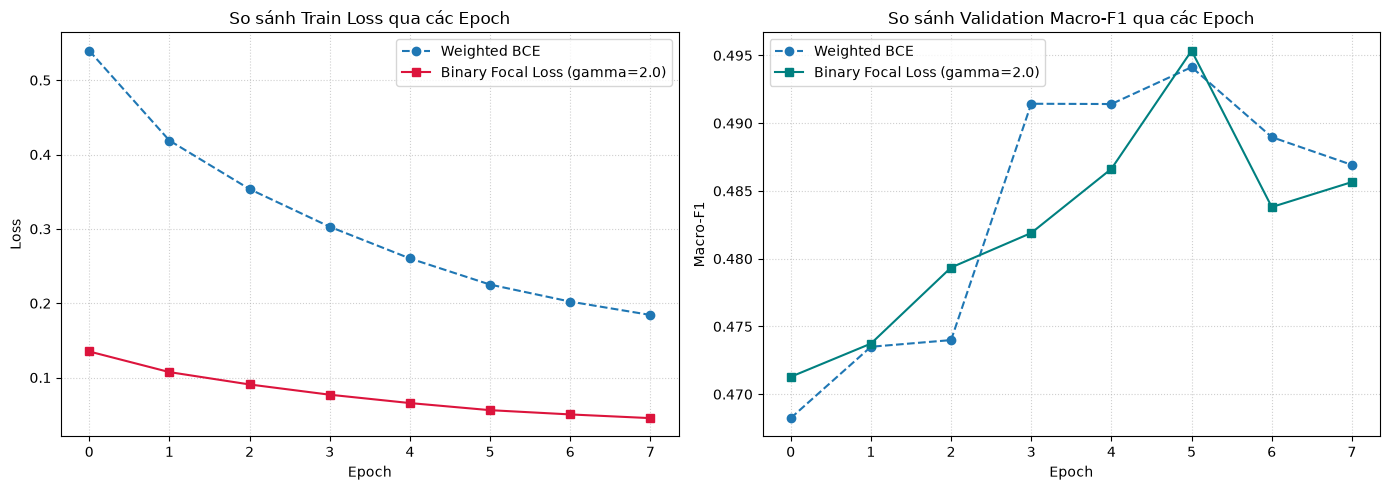

In [9]:
os.makedirs("../assets", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_bce["train_loss"], label="Weighted BCE", marker="o", linestyle="--")
axes[0].plot(hist_focal["train_loss"], label="Binary Focal Loss (gamma=2.0)", marker="s", color="crimson")
axes[0].set_title("So sánh Train Loss qua các Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(hist_bce["val_macro_f1"], label="Weighted BCE", marker="o", linestyle="--")
axes[1].plot(hist_focal["val_macro_f1"], label="Binary Focal Loss (gamma=2.0)", marker="s", color="teal")
axes[1].set_title("So sánh Validation Macro-F1 qua các Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("../assets/bilstm_loss_comparison.png", dpi=150)
plt.show()

Cell 7 (Bấm nút + Code): Đánh giá trên tập Test & Vẽ Ma trận nhầm lẫn

=== KẾT QUẢ TRÊN TẬP TEST (Macro-F1: 0.5022) ===

              precision    recall  f1-score   support

       toxic       0.53      0.69      0.60       637
        hate       0.39      0.70      0.50       326
        spam       0.00      0.00      0.00         0
       clean       0.94      0.88      0.91      3361

   micro avg       0.79      0.84      0.82      4324
   macro avg       0.46      0.57      0.50      4324
weighted avg       0.84      0.84      0.83      4324
 samples avg       0.84      0.85      0.84      4324



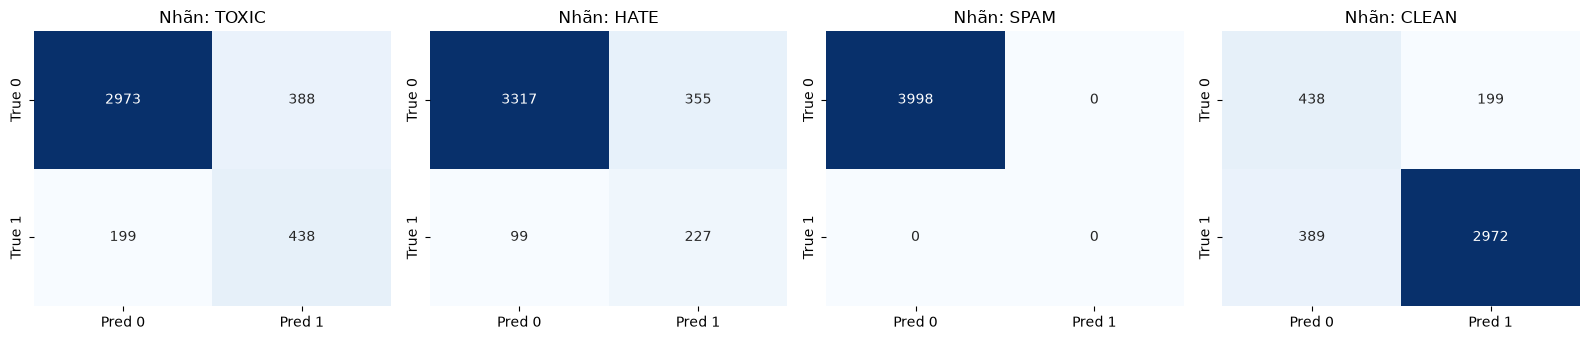

In [10]:
best_model = BiLSTMAttention(vocab_size=len(vocab), embed_dim=128, hidden_dim=128, num_classes=4).to(device)
best_model.load_state_dict(torch.load("../checkpoints/best_bilstm.pth", map_location=device))

test_f1, y_true, y_pred, y_probs = evaluate_model(best_model, test_loader, device, threshold=0.5)
print(f"=== KẾT QUẢ TRÊN TẬP TEST (Macro-F1: {test_f1:.4f}) ===\n")
print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0))

mcm = multilabel_confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for idx, (matrix, label) in enumerate(zip(mcm, LABEL_COLS)):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    axes[idx].set_title(f"Nhãn: {label.upper()}")

plt.tight_layout()
plt.savefig("../assets/bilstm_confusion_matrices.png", dpi=150)
plt.show()

Cell 8 (Bấm nút + Code): Phân tích lỗi sai & Trực quan hóa trọng số Attention

Số mẫu dự đoán sai ít nhất 1 nhãn: 758 / 3998

Câu: Con cho
  -> Thật: ['toxic'] | Dự đoán: ['toxic', 'hate']

Câu: đang ngó ngó nó thả cho quả boom khả_năng đen luôn
  -> Thật: ['clean'] | Dự đoán: ['toxic', 'hate']

Câu: Thật đau_lòng khi sự_việc xảy ra trong thời_gian dài . Chỉ đến khi các cháu bỏ trốn về bà nội kêu cứu mới được phát_hiện .
  -> Thật: ['toxic'] | Dự đoán: ['clean']

Câu: Nhìn mặt_mày dao kéo nhiều quá rồi đẹp gì ghê quá
  -> Thật: ['toxic', 'hate'] | Dự đoán: ['clean']

Câu: Hành_động vô_lương_tâm thật !
  -> Thật: ['toxic'] | Dự đoán: ['clean']

Xác suất dự đoán: {'toxic': 0.707, 'hate': 0.707, 'spam': 0.026, 'clean': 0.294}


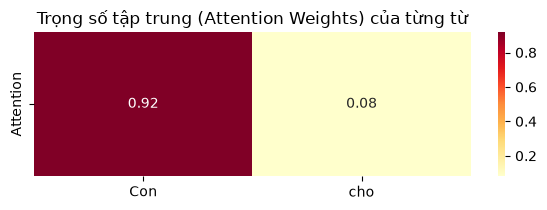

In [11]:
test_df = pd.read_csv(TEST_PATH, encoding="utf-8")

# 1. In ra 5 ví dụ dự đoán sai
mismatch_mask = (y_true != y_pred).any(axis=1)
error_indices = np.where(mismatch_mask)[0]
print(f"Số mẫu dự đoán sai ít nhất 1 nhãn: {len(error_indices)} / {len(test_df)}\n")

for idx in error_indices[:5]:
    true_lbl = [LABEL_COLS[i] for i, v in enumerate(y_true[idx]) if v == 1]
    pred_lbl = [LABEL_COLS[i] for i, v in enumerate(y_pred[idx]) if v == 1]
    print(f"Câu: {test_df.loc[idx, 'text_processed']}")
    print(f"  -> Thật: {true_lbl} | Dự đoán: {pred_lbl}\n")

# 2. Trực quan hóa trọng số Attention trên 1 câu mẫu độc hại
def visualize_attention(sentence: str):
    best_model.eval()
    tokens = sentence.split()[:MAX_LEN]
    input_ids = torch.tensor([vocab.encode(sentence, MAX_LEN)], dtype=torch.long).to(device)
    mask = (input_ids != 0).float()

    with torch.no_grad():
        embedded = best_model.embedding(input_ids)
        lstm_out, _ = best_model.lstm(embedded)
        context, attn_weights = best_model.attention(lstm_out, mask=mask)
        probs = torch.sigmoid(best_model.fc(context)).cpu().numpy()[0]

    weights = attn_weights.cpu().numpy()[0][:len(tokens)]
    print("Xác suất dự đoán:", {lbl: round(float(p), 3) for lbl, p in zip(LABEL_COLS, probs)})

    plt.figure(figsize=(max(6, len(tokens) * 0.9), 2.2))
    sns.heatmap([weights], annot=True, fmt=".2f", cmap="YlOrRd", xticklabels=tokens, yticklabels=["Attention"])
    plt.title("Trọng số tập trung (Attention Weights) của từng từ")
    plt.tight_layout()
    plt.show()

sample_sentence = test_df[test_df["toxic"] == 1]["text_processed"].dropna().iloc[0]
visualize_attention(sample_sentence)